# **1. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import seaborn as sns
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

# **2. Memuat Dataset dari Hasil Clustering**

Memuat dataset hasil clustering dari file CSV ke dalam variabel DataFrame.

In [2]:
data = pd.read_csv('bank_transactions_clustered.csv')

print(data.head())

data.info()

   CustomerAge  Channel  TransactionType  Location  TransactionDuration  \
0     1.423718        0                1        36            -0.552443   
1     1.311287        0                1        15             0.305314   
2    -1.443277        2                1        23            -0.909842   
3    -1.049768        2                1        33            -1.353017   
4    -1.049768        2                0         1             1.120184   

   Cluster  
0        0  
1        1  
2        1  
3        0  
4        2  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerAge          2512 non-null   float64
 1   Channel              2512 non-null   int64  
 2   TransactionType      2512 non-null   int64  
 3   Location             2512 non-null   int64  
 4   TransactionDuration  2512 non-null   float64
 5   Cluster   

# **3. Data Splitting**

Tahap Data Splitting bertujuan untuk memisahkan dataset menjadi dua bagian: data latih (training set) dan data uji (test set).

In [3]:
label_encoder = LabelEncoder()
categorical_columns = ['Channel', 'TransactionType', 'Location']
for column in categorical_columns:
    data[column] = label_encoder.fit_transform(data[column])
print(data.head())

scaler = MinMaxScaler()
data['Cluster'] = data['Cluster'].astype('category')
print(data.head())

numeric_columns = data.select_dtypes(include=['int64', 'float64']).columns
data[numeric_columns] = scaler.fit_transform(data[numeric_columns])

X = data.drop(columns=['Cluster'])
y = data['Cluster']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape}")

   CustomerAge  Channel  TransactionType  Location  TransactionDuration  \
0     1.423718        0                1        36            -0.552443   
1     1.311287        0                1        15             0.305314   
2    -1.443277        2                1        23            -0.909842   
3    -1.049768        2                1        33            -1.353017   
4    -1.049768        2                0         1             1.120184   

   Cluster  
0        0  
1        1  
2        1  
3        0  
4        2  
   CustomerAge  Channel  TransactionType  Location  TransactionDuration  \
0     1.423718        0                1        36            -0.552443   
1     1.311287        0                1        15             0.305314   
2    -1.443277        2                1        23            -0.909842   
3    -1.049768        2                1        33            -1.353017   
4    -1.049768        2                0         1             1.120184   

  Cluster  
0       

# **4. Membangun Model Klasifikasi**


## **a. Membangun Model Klasifikasi**

Setelah memilih algoritma klasifikasi yang sesuai, langkah selanjutnya adalah melatih model menggunakan data latih.

Berikut adalah rekomendasi tahapannya.
1. Pilih algoritma klasifikasi yang sesuai, seperti Logistic Regression, Decision Tree, Random Forest, atau K-Nearest Neighbors (KNN).
2. Latih model menggunakan data latih.

In [4]:
# Melatih model klasifikasi dengan data latih
knn = KNeighborsClassifier().fit(X_train, y_train)
dt = DecisionTreeClassifier().fit(X_train, y_train)
rf = RandomForestClassifier().fit(X_train, y_train)
svm = SVC().fit(X_train, y_train)
nb = GaussianNB().fit(X_train, y_train)

print("Training Model Finished.")

Training Model Finished.


Tulis narasi atau penjelasan algoritma yang Anda gunakan.

1. K-Nearest Neighbors (KNN): Algoritma ini menentukan kelas suatu data baru dengan melihat beberapa data terdekatnya. Misalnya, jika mayoritas tetangga terdekatnya termasuk dalam kategori A, maka data baru tersebut juga dikategorikan sebagai A. Jarak antar data biasanya dihitung menggunakan metode seperti Euclidean.
2. Decision Tree: Algoritma ini membuat pohon keputusan untuk menentukan hasil berdasarkan fitur-fitur dalam data. Setiap percabangan dalam pohon mewakili keputusan tertentu, sehingga prosesnya mirip seperti menjawab serangkaian pertanyaan "ya" atau "tidak" untuk sampai ke kesimpulan.
3. Random Forest: Algoritma ini adalah versi yang lebih canggih dari Decision Tree. Algoritma ini membuat banyak pohon keputusan dan menggabungkan hasilnya untuk mendapatkan prediksi yang lebih akurat dan stabil. Ibaratnya seperti meminta pendapat dari banyak ahli sebelum mengambil keputusan.
4. Support Vector Machine (SVM): Algoritma ini mencari garis atau bidang pemisah terbaik untuk membedakan dua kelompok data. SVM berusaha mencari pemisah yang memiliki jarak terbesar dari kedua kelompok agar prediksi lebih akurat.
5. Naive Bayes: Algoritma berbasis probabilitas yang menggunakan Teorema Bayes untuk memprediksi kategori data. Meskipun sederhana, algoritma ini sangat efektif untuk klasifikasi teks, seperti mendeteksi spam dalam email.



## **b. Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Lakukan prediksi menggunakan data uji.
2. Hitung metrik evaluasi seperti Accuracy dan F1-Score (Opsional: Precision dan Recall).
3. Buat confusion matrix untuk melihat detail prediksi benar dan salah.

In [5]:
# Fungsi untuk mengevaluasi model
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    results = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1-Score': f1_score(y_test, y_pred, average='weighted')
    }
    return results

# Mengevaluasi setiap model
results = {
    'K-Nearest Neighbors (KNN)': evaluate_model(knn, X_test, y_test),
    'Decision Tree (DT)': evaluate_model(dt, X_test, y_test),
    'Random Forest (RF)': evaluate_model(rf, X_test, y_test),
    'Support Vector Machine (SVM)': evaluate_model(svm, X_test, y_test),
    'Naive Bayes (NB)': evaluate_model(nb, X_test, y_test)
}

# Membuat DataFrame untuk merangkum hasil evaluasi
summary_df = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])

# Menambahkan hasil evaluasi ke DataFrame
rows = []
for model_name, metrics in results.items():
    rows.append({
        'Model': model_name,
        'Accuracy': metrics['Accuracy'],
        'Precision': metrics['Precision'],
        'Recall': metrics['Recall'],
        'F1-Score': metrics['F1-Score']
    })

# Mengonversi hasil evaluasi menjadi DataFrame
summary_df = pd.DataFrame(rows)

# Menampilkan DataFrame hasil evaluasi
print(summary_df)

                          Model  Accuracy  Precision    Recall  F1-Score
0     K-Nearest Neighbors (KNN)  0.922465   0.922801  0.922465  0.922596
1            Decision Tree (DT)  1.000000   1.000000  1.000000  1.000000
2            Random Forest (RF)  1.000000   1.000000  1.000000  1.000000
3  Support Vector Machine (SVM)  0.984095   0.984095  0.984095  0.984095
4              Naive Bayes (NB)  1.000000   1.000000  1.000000  1.000000


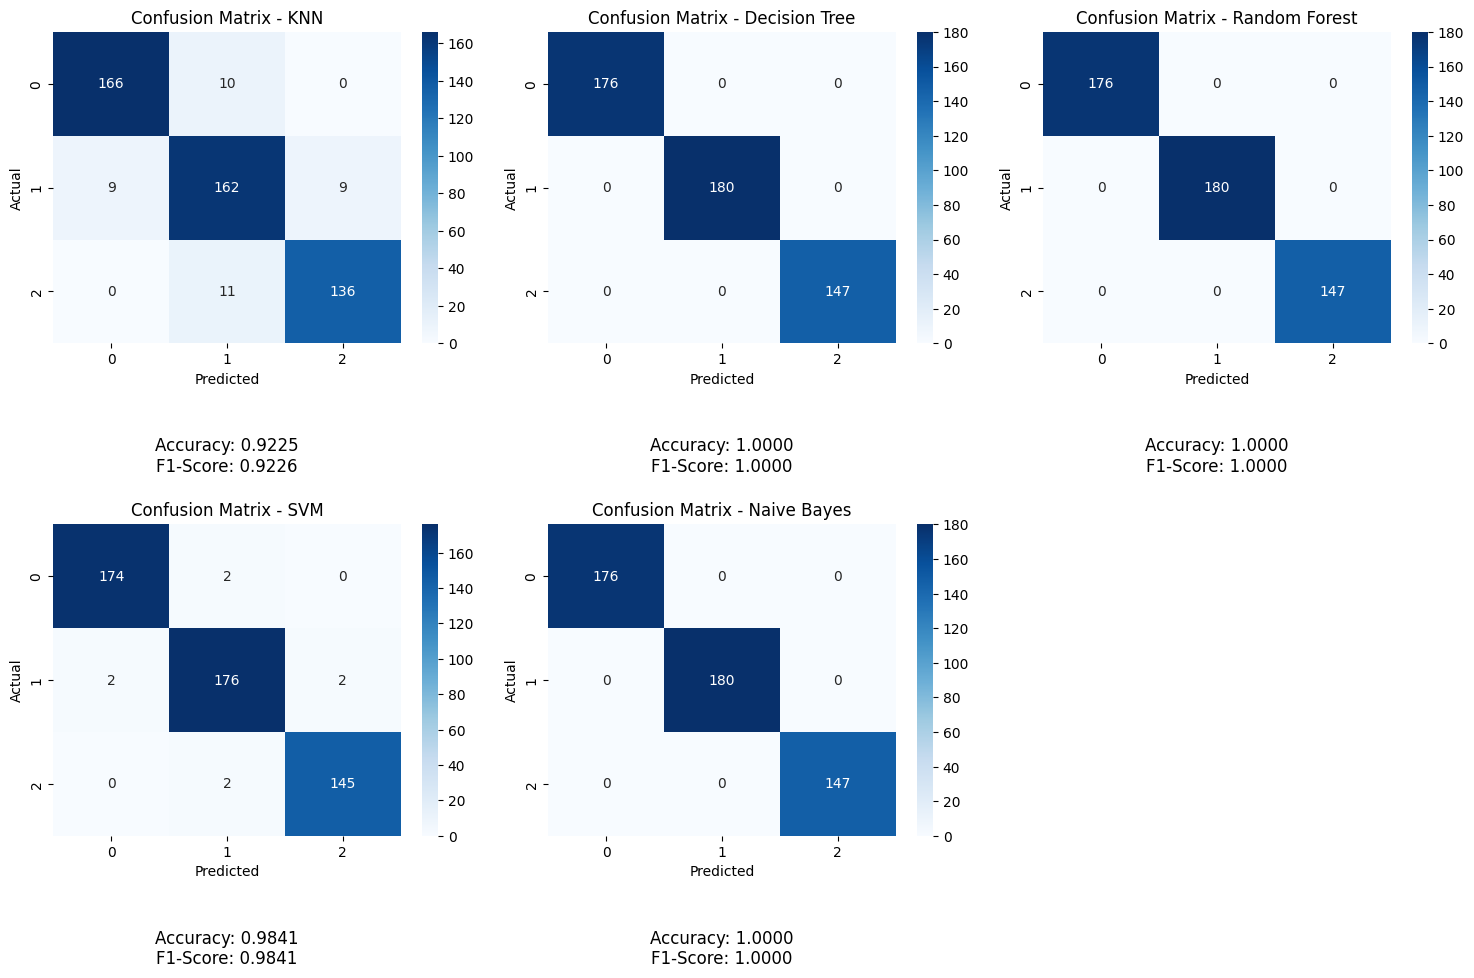

In [6]:
def plot_confusion_matrices(models, X_test, y_test, model_names):
    num_models = len(models)
    cols = 3  # Maksimal 3 plot per baris
    rows = (num_models // cols) + (num_models % cols > 0)  # Hitung jumlah baris yang dibutuhkan

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))  # Ukuran plot
    axes = axes.flatten()  # Ubah jadi array 1D agar lebih mudah diakses

    for i, (model, name) in enumerate(zip(models, model_names)):
        y_pred = model.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)

        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=np.unique(y_test), yticklabels=np.unique(y_test),
                    ax=axes[i])
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("Actual")
        axes[i].set_title(f"Confusion Matrix - {name}")

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average='weighted')

        # Tambahkan teks akurasi di bawah plot
        axes[i].text(0.5, -0.3, f"Accuracy: {acc:.4f}\nF1-Score: {f1:.4f}",
                     ha="center", va="top", transform=axes[i].transAxes, fontsize=12)

    # Hapus subplot kosong jika jumlah model tidak kelipatan 3
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

# Daftar model dan namanya
models = [knn, dt, rf, svm, nb]
model_names = ["KNN", "Decision Tree", "Random Forest", "SVM", "Naive Bayes"]

# Plot confusion matrices dalam grid 3 kolom
plot_confusion_matrices(models, X_test, y_test, model_names)


Tulis hasil evaluasi algoritma yang digunakan, jika Anda menggunakan 2 algoritma, maka bandingkan hasilnya.

# Evaluasi Algoritma Klasifikasi Berdasarkan Confusion Matrix

1. K-Nearest Neighbors (KNN)

    Akurasi: 92.25%

    F1-Score: 92.26%
    
    Analisis:
  *   KNN memiliki performa yang cukup baik, tetapi masih terdapat beberapa kesalahan klasifikasi.
  *   Beberapa sampel dari kelas 1 dan 2 diklasifikasikan secara salah, yang menyebabkan sedikit penurunan performa dibandingkan algoritma lain.
  *   Hal ini menunjukkan bahwa KNN sedikit kesulitan dalam membedakan batas antar kelas tertentu, kemungkinan karena kedekatan jarak antar fitur yang mirip.
2. Decision Tree

    Akurasi: 100%

    F1-Score: 100%

    Analisis:
  * Decision Tree berhasil mengklasifikasikan semua sampel dengan benar, tanpa ada kesalahan prediksi.
  * Kemungkinan model ini mengalami overfitting, di mana ia terlalu menyesuaikan diri dengan data latih sehingga performanya bisa menurun jika diuji dengan data baru yang berbeda.

3. Random Forest

    Akurasi: 100%

    F1-Score: 100%

    Analisis:

  * Seperti Decision Tree, Random Forest juga berhasil mengklasifikasikan semua data dengan benar.
  * Random Forest lebih stabil dibandingkan Decision Tree karena merupakan kombinasi dari beberapa pohon keputusan, sehingga mengurangi kemungkinan overfitting.
  * Algoritma ini sering menjadi pilihan utama karena kombinasi akurasi tinggi dan generalisasi yang baik.

4. Support Vector Machine (SVM)

    Akurasi: 98.41%

    F1-Score: 98.41%

    Analisis:

  * SVM juga memiliki performa yang sangat baik, meskipun masih terdapat sedikit kesalahan klasifikasi.
  * Model ini sangat efektif dalam menemukan hyperplane pemisah antar kelas, tetapi mungkin memerlukan tuning parameter agar lebih optimal.

5. Naive Bayes

    Akurasi: 100%

    F1-Score: 100%

    Analisis:
    * Naive Bayes juga menghasilkan klasifikasi sempurna.
    * Meski sederhana, algoritma ini sangat efektif terutama jika fitur relatif independen.



## **c. Tuning Model Klasifikasi (Optional)**

Gunakan GridSearchCV, RandomizedSearchCV, atau metode lainnya untuk mencari kombinasi hyperparameter terbaik

In [7]:
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(estimator=RandomForestClassifier(), param_grid=param_grid, cv=3, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
best_rf = grid_search.best_estimator_
best_rf_results = evaluate_model(best_rf, X_test, y_test)
print("Best Random Forest Results:", best_rf_results)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best Random Forest Results: {'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1-Score': 1.0}


## **d. Evaluasi Model Klasifikasi setelah Tuning (Optional)**

Berikut adalah rekomendasi tahapannya.
1. Gunakan model dengan hyperparameter terbaik.
2. Hitung ulang metrik evaluasi untuk melihat apakah ada peningkatan performa.

In [8]:
# Membandingkan hasil sebelum dan sesudah tuning
print("Hasil Sebelum Tuning:")
print(summary_df[summary_df['Model'] == 'Random Forest (RF)'])

print("\nHasil Setelah Tuning:")
print(best_rf_results)

Hasil Sebelum Tuning:
                Model  Accuracy  Precision  Recall  F1-Score
2  Random Forest (RF)       1.0        1.0     1.0       1.0

Hasil Setelah Tuning:
{'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1-Score': 1.0}


## **e. Analisis Hasil Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Bandingkan hasil evaluasi sebelum dan setelah tuning (jika dilakukan).
2. Identifikasi kelemahan model, seperti:
  - Precision atau Recall rendah untuk kelas tertentu.
  - Apakah model mengalami overfitting atau underfitting?
3. Berikan rekomendasi tindakan lanjutan, seperti mengumpulkan data tambahan atau mencoba algoritma lain jika hasil belum memuaskan.

1. Tidak ada perubahan dalam performa model sebelum dan setelah tuning karena nilai akurasi, precision, recall, dan F1-score tetap 1.0 (100%). Hal ini menunjukkan bahwa model Random Forest sudah optimal bahkan sebelum dilakukan tuning, atau dataset yang digunakan memiliki pola yang sangat mudah diklasifikasikan. Tuning tidak berdampak signifikan karena model sudah mencapai performa maksimal.

2. Identifikasi Kelemahan Model
* Precision atau recall rendah
  *   K-Nearest Neighbors (KNN) Memiliki performa lebih rendah dibanding model lainnya (akurasi 92.25%). Precision dan recall tidak mencapai 1.0, artinya ada beberapa prediksi yang salah. Kelemahan ini bisa terjadi karena KNN sensitif terhadap data yang tidak terdistribusi dengan baik atau terhadap fitur yang memiliki skala berbeda.

  * Support Vector Machine (SVM) Performa cukup tinggi (akurasi 98.41%), tetapi masih lebih rendah dibanding DT, RF, dan NB yang mencapai 100%. Hal ini menunjukkan bahwa SVM mengalami kesulitan dalam memisahkan beberapa kelas. Ini bisa terjadi karena data tidak sepenuhnya terpisah secara linear, sehingga kernel yang digunakan mungkin kurang optimal.
* Apakah Model Mengalami Overfitting atau Underfitting?
  * Decision Tree, Random Forest, dan Naive Bayes memiliki akurasi 100% di data uji. Kemungkinan besar terjadi overfitting, terutama pada Decision Tree, karena model ini cenderung menangkap noise dari data latih. Random Forest lebih tahan terhadap overfitting, tetapi tetap perlu diuji dengan dataset lain atau melalui cross-validation untuk memastikan generalisasi model.
  * KNN dan SVM tidak mencapai 100% akurasi, yang berarti lebih realistis dan mungkin lebih generalizable ke data baru. KKN cenderung underfitting jika tidak dipilih jumlah tetangga (k) yang tepat. SVM bisa mengalami underfitting jika parameter C terlalu kecil, sehingga perlu dicoba tuning parameter.

